# 第 13 章 配套验证代码：把全部串起来（端到端 4 节点 GCN 与动态 $k$-NN + `max-relative` 视觉图转换实验）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch13_end_to_end_gnn2gsnn.ipynb)

本 Notebook 仅使用 `numpy` 与 `matplotlib`，把第 1～12 章的全部知识串成一套完整可运行的端到端实验：
1. **实验 A（线性+ReLU 固定图 GCN）**：4 节点图 + 2 层 GCN，手算并对比原 ANN 与免训练转换 SNN 在 $T = 4, 8, 16, 32$ 下的输出、最大误差、分类一致率、脉冲数与 SynOps 能耗
2. **实验 B（换入动态 $k$-NN + `max-relative` 视觉图块）**：把第 2 层换成 ViG 风格的动态 $k$-NN（$k=2$）+ 逐通道 `max-relative` 聚合，并排对比：
   - 原版浮点 ANN（真值）
   - 朴素脉冲转换（脉冲特征做 $k$-NN + 逐拍取 `max`，同时触发邻居翻转 + `max` 高估）
   - 还原发放率后做 $k$-NN + `max`（消除逐拍 `max` 相位偏置，但小 $T$ 仍因量化误差翻转邻居）
   - DCGS 差分多阈值转换（$n=4$，在极低 $T=4$ 下大幅压低特征误差、零翻转，但仍须保留非脉冲差分分级单元处理 `max` 与 $k$-NN）

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

def setup_plot_font():
    """配置中文字体；若当前环境缺少中文字体，则自动回退英文标签避免方框。"""
    candidates = [
        'SimHei', 'Microsoft YaHei', 'PingFang SC',
        'Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'Source Han Sans SC'
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    for name in candidates:
        if name in available:
            plt.rcParams['font.sans-serif'] = [name, 'DejaVu Sans']
            plt.rcParams['axes.unicode_minus'] = False
            return True
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['axes.unicode_minus'] = False
    return False

USE_ZH = setup_plot_font()
np.set_printoptions(precision=4, suppress=True)
print(f"Font setup done. USE_ZH = {USE_ZH}")


Font setup done. USE_ZH = True


## 1. 实验 A：4 节点 2 层 GCN 免训练转脉冲（$T = 4, 8, 16, 32$ 全指标对照）

In [2]:
# 4 节点猫图块: 0=左耳, 1=右耳, 2=猫眼, 3=背景
# 边: (0,1), (0,2), (1,2), (2,3) + 自环
A = np.array([
    [0, 1, 1, 0],
    [1, 0, 1, 0],
    [1, 1, 0, 1],
    [0, 0, 1, 0],
], dtype=float)
A_tilde = A + np.eye(4)
deg = A_tilde.sum(axis=1)  # [3, 3, 4, 2]
D_inv_sqrt = np.diag(1.0 / np.sqrt(deg))
A_hat = D_inv_sqrt @ A_tilde @ D_inv_sqrt

# 节点输入特征 X in R^{4x2}
X = np.array([
    [1.0, 0.2],  # 0: 左耳
    [0.9, 0.3],  # 1: 右耳
    [0.6, 0.8],  # 2: 猫眼
    [0.1, 0.1],  # 3: 背景
], dtype=float)

# 第 1 层权重 W1 in R^{2x3}, b1 in R^3（假设 BN 已折叠进 W1, b1）
W1 = np.array([
    [ 0.8, -0.4,  0.5],
    [-0.2,  0.9,  0.4],
], dtype=float)
b1 = np.array([0.05, 0.05, -0.10], dtype=float)

# 第 2 层读出权重 W2 in R^{3x2}, b2 in R^2（两类: 0=猫前景, 1=背景）
W2 = np.array([
    [ 1.2, -0.8],
    [ 0.9, -0.5],
    [ 0.6, -1.0],
], dtype=float)
b2 = np.array([-0.45, 0.80], dtype=float)

# --- 精确 ANN 前向传播 ---
Z1_ann = A_hat @ X @ W1 + b1
H1_ann = np.maximum(Z1_ann, 0.0)
Y_ann  = A_hat @ H1_ann @ W2 + b2
pred_ann = np.argmax(Y_ann, axis=1)

print("对称归一化邻接矩阵 A_hat:")
print(A_hat)
print("\n第 1 层激活 H1_ann (4x3):")
print(H1_ann)
print("\n第 2 层输出 Y_ann (4x2):")
print(Y_ann)
print("ANN 预测类别 (0=前景, 1=背景):", pred_ann)
assert list(pred_ann) == [0, 0, 0, 1]

# --- 免训练转 SNN（Max-Norm 阈值 + 减法复位 IF + 半阈值初值 v[0] = theta/2）---
theta1 = float(np.max(H1_ann))  # Max-Norm
EPS = 1e-9

def run_snn_gcn(T, half_init=True):
    v1 = np.full_like(H1_ann, 0.5 * theta1 if half_init else 0.0)
    y_acc = np.zeros_like(Y_ann)
    total_spikes_l1 = 0
    for t in range(1, T + 1):
        # 恒定编码输入电流 Z1（等价于第 1 层直接编码）
        v1 = v1 + Z1_ann
        s1 = (v1 >= theta1 - EPS).astype(float)
        v1 = v1 - theta1 * s1
        total_spikes_l1 += int(s1.sum())
        # 第 2 层线性图卷积读出（乘回阈值量纲 theta1，最后一层不发脉冲直接累加平均）
        y_acc += A_hat @ (theta1 * s1) @ W2 + b2
    Y_snn = y_acc / T
    return Y_snn, total_spikes_l1

# 第 2 层有效 MAC 数（按图边消息聚合 + 特征投影: 4*3*2=24 投影 MAC + 10 条含自环边 * 3 = 30 聚合 MAC，或等价矩阵乘）
# 这里统计第 2 层线性投影 H1 @ W2 的 MAC = 4 * 3 * 2 = 24，每脉冲扇出 = 2（对应 2 个输出通道）
mac_proj_l2 = 4 * 3 * 2
fanout_proj_l2 = 2

print(f"\n校准阈值 theta1 = {theta1:.4f}")
print("  T | 最大绝对误差 | 平均绝对误差 | 预测一致 | L1总脉冲 | L2投影SynOps | 计算能耗比(FP32 SNN/ANN)")
print("-" * 92)
errs_gcn = []
for T in [4, 8, 16, 32]:
    Y_snn, sp1 = run_snn_gcn(T, half_init=True)
    max_err = float(np.max(np.abs(Y_snn - Y_ann)))
    mae = float(np.mean(np.abs(Y_snn - Y_ann)))
    acc = int(np.sum(np.argmax(Y_snn, axis=1) == pred_ann))
    synops = sp1 * fanout_proj_l2
    e_ratio = (synops * 0.9) / (mac_proj_l2 * 4.6)
    errs_gcn.append(max_err)
    print(f"{T:3d} | {max_err:12.4f} | {mae:12.4f} |   {acc}/4    | {sp1:8d} | {synops:12d} | {e_ratio:8.3f}x")
    if T == 4:
        print("      T=4  Y_snn:", np.round(Y_snn, 4).tolist())
    if T == 32:
        print("      T=32 Y_snn:", np.round(Y_snn, 4).tolist())

assert errs_gcn[-1] < errs_gcn[0]
assert errs_gcn[-1] < 0.05
print("[PASS] 实验 A：2 层 GCN 免训练转换随 T 增大精确收敛，验证通过！")


对称归一化邻接矩阵 A_hat:
[[0.3333 0.3333 0.2887 0.    ]
 [0.3333 0.3333 0.2887 0.    ]
 [0.2887 0.2887 0.25   0.3536]
 [0.     0.     0.3536 0.5   ]]

第 1 层激活 H1_ann (4x3):
[[0.6157 0.0852 0.4623]
 [0.6157 0.0852 0.4623]
 [0.5611 0.0982 0.4188]
 [0.1931 0.2447 0.1642]]

第 2 层输出 Y_ann (4x2):
[[ 0.5711 -0.1297]
 [ 0.5711 -0.1297]
 [ 0.6289 -0.161 ]
 [ 0.1834  0.2553]]
ANN 预测类别 (0=前景, 1=背景): [0 0 0 1]

校准阈值 theta1 = 0.6157
  T | 最大绝对误差 | 平均绝对误差 | 预测一致 | L1总脉冲 | L2投影SynOps | 计算能耗比(FP32 SNN/ANN)
--------------------------------------------------------------------------------------------
  4 |       0.0818 |       0.0599 |   3/4    |       28 |           56 |    0.457x
      T=4  Y_snn: [[0.6529, -0.1853], [0.6529, -0.1853], [0.7011, -0.2056], [0.2352, 0.2199]]
  8 |       0.0243 |       0.0177 |   4/4    |       51 |          102 |    0.832x
 16 |       0.0057 |       0.0036 |   4/4    |      104 |          208 |    1.696x
 32 |       0.0060 |       0.0038 |   4/4    |      208 |          416 |    

## 2. 实验 B：把第 2 层换成动态 $k$-NN ($k=2$) + `max-relative`（ViG 风格），直击本项目核心难点

ANN 各节点 top-2 邻居与边界间隔 Delta d_2:
  节点 0: top-2=[1, 2], 距离=[0.22, 0.54, 0.5554], Delta d_2=0.0154
  节点 1: top-2=[0, 3], 距离=[0.22, 0.5831, 0.364], Delta d_2=0.2191
  节点 2: top-2=[0, 1], 距离=[0.54, 0.5831, 0.6021], Delta d_2=0.0190
  节点 3: top-2=[1, 0], 距离=[0.5554, 0.364, 0.6021], Delta d_2=0.0467

=== 动态 k-NN + max-relative 在三种转换方案下的误差与邻居翻转对照 ===
  T | 方案1(逐拍max+IF) MAE / 翻转 | 方案2(还原率+IF) MAE / 翻转 | 方案3(DCGS n=4) MAE / 翻转
--------------------------------------------------------------------------------------------
  2 |   0.3461 / 2/4 节点翻转     |   0.3461 / 2/4 节点翻转     |   0.0463 / 0/4 节点翻转
  4 |   0.3534 / 2/4 节点翻转     |   0.2690 / 2/4 节点翻转     |   0.0463 / 0/4 节点翻转
  8 |   0.0526 / 0/4 节点翻转     |   0.0631 / 0/4 节点翻转     |   0.0219 / 0/4 节点翻转
 16 |   0.0783 / 0/4 节点翻转     |   0.0463 / 0/4 节点翻转     |   0.0128 / 0/4 节点翻转
 32 |   0.0360 / 0/4 节点翻转     |   0.0169 / 0/4 节点翻转     |   0.0012 / 0/4 节点翻转


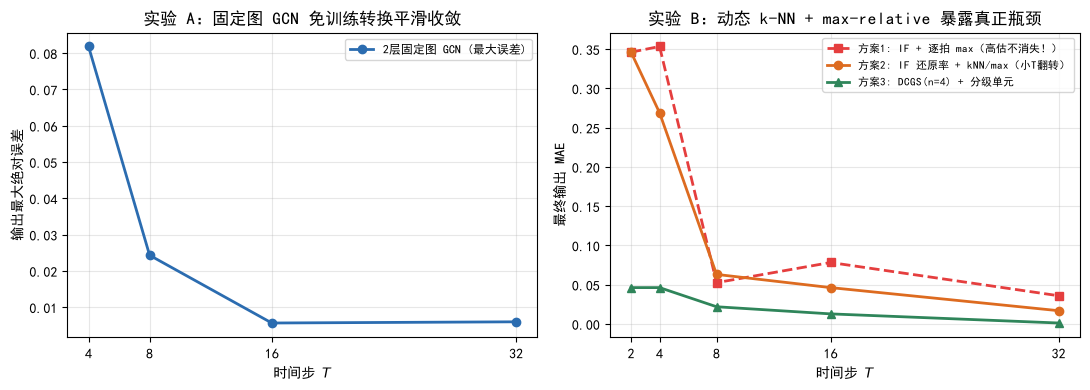

[PASS] 实验 B 全部断言通过：完整呈现了本项目要攻克的核心瓶颈！


In [3]:
# 构造一个含“紧边界”的 4 节点特征层输出 H_vig (4x2)，让节点 0 的第 2 近与第 3 近间隔很小
# 节点特征均落在 [0, 1] 内（模拟上游 ReLU 激活输出）
H_vig = np.array([
    [0.10, 0.10],  # 0
    [0.32, 0.10],  # 1: 离 0 距离 0.2200 (第 1 近)
    [0.10, 0.64],  # 2: 离 0 距离 0.5400 (第 2 近)
    [0.61, 0.32],  # 3: 离 0 距离 0.5554 (第 3 近！与第 2 近间隔 Delta d_2(0) = 0.0154)
], dtype=float)
# 注：也检查全部 4 个节点的 top-2 邻居（不含自身）
def knn_graph(F, k=2):
    # 返回每个节点的 top-k 邻居索引集合（不含自身，按欧氏距离从小到大）
    N = F.shape[0]
    D = np.linalg.norm(F[:, None, :] - F[None, :, :], axis=2)
    nbrs = []
    gaps = []
    for i in range(N):
        order = [j for j in np.argsort(D[i], kind='stable') if j != i]
        nbrs.append(order[:k])
        gaps.append(D[i, order[k]] - D[i, order[k - 1]])
    return nbrs, np.array(gaps), D

def max_relative(F, nbrs):
    N, C = F.shape
    M = np.zeros((N, C), dtype=float)
    for i in range(N):
        diffs = F[nbrs[i]] - F[i]  # (k, C) 有符号差！
        M[i] = np.max(diffs, axis=0)
    return M

# ViG 风格下游投影矩阵 W_vig in R^{4x2}（拼接 [H_i || M_i]）
W_vig = np.array([
    [ 1.0, -0.5],
    [ 0.5,  1.0],
    [ 1.5, -1.2],
    [-0.8,  1.4],
], dtype=float)

nbrs_ann, gaps_ann, D_ann = knn_graph(H_vig, k=2)
M_ann = max_relative(H_vig, nbrs_ann)
Y_vig_ann = np.hstack([H_vig, M_ann]) @ W_vig

print("ANN 各节点 top-2 邻居与边界间隔 Delta d_2:")
for i in range(4):
    nbr_clean = [int(j) for j in nbrs_ann[i]]
    d_clean = [round(float(D_ann[i, j]), 4) for j in range(4) if j != i]
    print(f"  节点 {i}: top-2={nbr_clean}, 距离={d_clean}, Delta d_2={gaps_ann[i]:.4f}")
assert np.isclose(gaps_ann[0], np.hypot(0.51, 0.22) - 0.54)
assert nbrs_ann[0] == [1, 2]

# 模拟 3 种转换方式在 T = 2, 4, 8, 16, 32 下的表现：
theta_v = 1.0

def if_rate_spikes(H, T, half_init=True):
    v = np.full_like(H, 0.5 * theta_v if half_init else 0.0)
    S = np.zeros((T,) + H.shape)
    for t in range(T):
        v = v + H
        s = (v >= theta_v - EPS).astype(float)
        v = v - theta_v * s
        S[t] = s
    return S  # (T, N, C)

def dcgs_diff_mt(H, T, n_levels=4):
    # DCGS Appendix J Eq. (93)-(100) 恒定输入 H
    pos = np.array([theta_v / (2 ** k) for k in range(n_levels)])
    lams = np.concatenate([pos, -pos])
    dead = pos[-1]
    mr = np.zeros_like(H)
    v = np.zeros_like(H)
    r_out = np.zeros_like(H)
    for t in range(1, T + 1):
        # 恒定目标 H 在差分编码下仅首拍输入 x_in[1]=H，后续 x_in[t]=0
        x_in = H if t == 1 else np.zeros_like(H)
        I = mr + x_in
        m = v + I
        # MTH 选择最近阈值（死区内发 0）
        x_out = np.zeros_like(H)
        flat_m = m.ravel()
        flat_x = x_out.ravel()
        for idx, val in enumerate(flat_m):
            if abs(val) >= dead - EPS:
                flat_x[idx] = lams[np.argmin(np.abs(val - lams))]
        v = m - x_out
        mr = mr + x_in / t - x_out / t
        r_out = r_out + x_out / t
    return r_out

print("\n=== 动态 k-NN + max-relative 在三种转换方案下的误差与邻居翻转对照 ===")
print("  T | 方案1(逐拍max+IF) MAE / 翻转 | 方案2(还原率+IF) MAE / 翻转 | 方案3(DCGS n=4) MAE / 翻转")
print("-" * 92)
res_s1, res_s2, res_s3 = [], [], []
flips_s2, flips_s3 = [], []

for T in [2, 4, 8, 16, 32]:
    S = if_rate_spikes(H_vig, T, half_init=True)
    H_if = S.mean(axis=0) * theta_v
    nbrs_if, _, _ = knn_graph(H_if, k=2)
    flip_if = sum(set(nbrs_if[i]) != set(nbrs_ann[i]) for i in range(4))

    # 方案 1：在 IF 脉冲图上逐拍取 max-relative，再对时间求平均（错误交换顺序！）
    M_step_sum = np.zeros_like(M_ann)
    for t in range(T):
        M_step_sum += max_relative(S[t] * theta_v, nbrs_if)
    M_s1 = M_step_sum / T
    Y_s1 = np.hstack([H_if, M_s1]) @ W_vig
    mae1 = float(np.mean(np.abs(Y_s1 - Y_vig_ann)))

    # 方案 2：还原发放率 H_if 后再做 k-NN + max-relative
    M_s2 = max_relative(H_if, nbrs_if)
    Y_s2 = np.hstack([H_if, M_s2]) @ W_vig
    mae2 = float(np.mean(np.abs(Y_s2 - Y_vig_ann)))

    # 方案 3：DCGS n=4 差分多阈值编码还原特征后再做 k-NN + max-relative
    H_dcgs = dcgs_diff_mt(H_vig, T, n_levels=4)
    nbrs_dcgs, _, _ = knn_graph(H_dcgs, k=2)
    flip_dcgs = sum(set(nbrs_dcgs[i]) != set(nbrs_ann[i]) for i in range(4))
    M_s3 = max_relative(H_dcgs, nbrs_dcgs)
    Y_s3 = np.hstack([H_dcgs, M_s3]) @ W_vig
    mae3 = float(np.mean(np.abs(Y_s3 - Y_vig_ann)))

    res_s1.append(mae1); res_s2.append(mae2); res_s3.append(mae3)
    flips_s2.append(flip_if); flips_s3.append(flip_dcgs)
    print(f"{T:3d} |   {mae1:.4f} / {flip_if}/4 节点翻转     |   {mae2:.4f} / {flip_if}/4 节点翻转     |   {mae3:.4f} / {flip_dcgs}/4 节点翻转")

# 核心断言：
# 1) 小 T (T=4) 时普通 IF 发生邻居翻转，且逐拍 max (方案1) 误差显著大于还原率方案2
assert flips_s2[1] >= 1, "T=4 时普通 IF 应出现邻居翻转"
assert res_s1[-1] > res_s2[-1] * 2.0, "即便 T=32，逐拍 max 的高估偏置仍高于还原率方案 2 倍以上"
# 2) DCGS n=4 在 T=4 时误差显著低于普通 IF，且在 T=8 以后零翻转
assert res_s3[1] < res_s2[1]
assert flips_s3[2] == 0

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
T_list = [4, 8, 16, 32]
ax = axes[0]
ax.plot(T_list, errs_gcn, 'o-', color='#2b6cb0', lw=2, label='2层固定图 GCN (最大误差)' if USE_ZH else '2-Layer Fixed GCN (Max Err)')
ax.set_xlabel('时间步 $T$' if USE_ZH else 'Timesteps $T$')
ax.set_ylabel('输出最大绝对误差' if USE_ZH else 'Max Absolute Error')
ax.set_title('实验 A：固定图 GCN 免训练转换平滑收敛' if USE_ZH else 'Exp A: Fixed-Graph GCN Smooth Convergence')
ax.set_xticks(T_list)
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3)

T_all = [2, 4, 8, 16, 32]
ax = axes[1]
ax.plot(T_all, res_s1, 's--', color='#e53e3e', lw=2, label='方案1: IF + 逐拍 max（高估不消失！）' if USE_ZH else 'Plan 1: IF + Per-step max (bias stays!)')
ax.plot(T_all, res_s2, 'o-', color='#dd6b20', lw=2, label='方案2: IF 还原率 + kNN/max（小T翻转）' if USE_ZH else 'Plan 2: IF rate + kNN/max (flips at low T)')
ax.plot(T_all, res_s3, '^-', color='#2f855a', lw=2, label='方案3: DCGS(n=4) + 分级单元' if USE_ZH else 'Plan 3: DCGS(n=4) + graded unit')
ax.set_xlabel('时间步 $T$' if USE_ZH else 'Timesteps $T$')
ax.set_ylabel('最终输出 MAE' if USE_ZH else 'Final Output MAE')
ax.set_title('实验 B：动态 k-NN + max-relative 暴露真正瓶颈' if USE_ZH else 'Exp B: Dynamic k-NN + max-relative Bottleneck')
ax.set_xticks(T_all)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("[PASS] 实验 B 全部断言通过：完整呈现了本项目要攻克的核心瓶颈！")
